## 1. 라이브러리 설치

In [ ]:
%pip install -q opendartreader pykrx finance-datareader yfinance fredapi ta PyPortfolioOpt
%pip install -q pandas numpy matplotlib requests python-dotenv
%pip install dart-fss

# opendartreader, dart-fss 둘 다 금융감독원 DART(전자공시시스템) OpenAPI를 파이썬에서 쓰기 쉽게 감싼 라이브러리
    # OpenDartReader: API 기능을 그대로 DataFrame으로 돌려주는 가볍고 단순한 도구
    # dart-fss: API에 더해 재무제표 추출과 분석까지 해주는 무거운 올인원 도구
# pykrx : KRX(한국거래소) 데이터, 주가, 시가총액, PER/PBR 같은 투자지표, 투자자별 수급 / 오픈소스
    # 라이브러리 git site : https://github.com/sharebook-kr/pykrx?utm_source=chatgpt.com
    # 라이센스 : https://github.com/sharebook-kr/pykrx/blob/master/pyproject.toml?utm_source=chatgpt.com
# finance-datareader : 한국·미국 주가, 지수, 환율, 종목 목록을 간단히 가져옴 / 오픈소스
    # 라이브러리 git site : https://github.com/sharebook-kr/pykrx?utm_source=chatgpt.com
    # 라이센스 : https://github.com/sharebook-kr/pykrx/blob/master/pyproject.toml?utm_source=chatgpt.com
# yfinance : Yahoo Finance에서 해외 주가, ETF, 지수, 배당 등 조회 / 오픈소스
    # 라이브러리 git site :  https://github.com/ranaroussi/yfinance?utm_source=chatgpt.com
# fredapi : 미국 연준(FRED)의 금리, 물가, 고용 등 거시경제 지표 / 오픈소스 
    # 라이브러리 git site : https://github.com/mortada/fredapi?utm_source=chatgpt.com
# ta : 기술적 지표 계산 (이동평균, RSI, MACD, 볼린저밴드 등) / 오픈소스 
    # 라이브러리 git site : https://github.com/bukosabino/ta?utm_source=chatgpt.com
# PyPortfolioOpt :  포트폴리오 최적화 (효율적 투자선, 샤프지수 최대화, 리스크 모델 등) / 오픈소스   
    # 라이브러리 git site : https://github.com/PyPortfolio/PyPortfolioOpt?utm_source=chatgpt.com

## 2. 환경 설정
* API 키는 환경변수나 같은 폴더의 .env 파일에서 읽음

**API 키 종류**

| 서비스 | 발급처 | 용도 |
|---|---|---|
| Open DART | opendart.fss.or.kr | 공시, 재무제표 |
| ECOS | ecos.bok.or.kr | 한국 거시통계 |
| 공공데이터포털 | data.go.kr | 금융위 주식시세 |
| FRED | fred.stlouisfed.org | 미국 거시통계 |
| KRX 데이터포털 계정 | data.krx.co.kr | pykrx 일부 함수 |

In [1]:
import os, platform, warnings
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib import font_manager
from dotenv import load_dotenv

warnings.filterwarnings("ignore")
load_dotenv()  # .env 내용을 OS 환경변수로 등록

#  각 API 키를 읽음. 없으면 None
DART_KEY = os.getenv("DART_API_KEY")
ECOS_KEY = os.getenv("ECOS_API_KEY")
DATA_KEY = os.getenv("DATA_GO_KR_KEY")
FRED_KEY = os.getenv("FRED_API_KEY")
# KRX 아이디와 비밀번호가 둘 다 있을 때만 True
KRX_OK = bool(os.getenv("KRX_ID") and os.getenv("KRX_PW"))   # pykrx 시가총액·투자지표·수급용

for name, key in {"DART": DART_KEY, "ECOS": ECOS_KEY, "DATA_GO_KR": DATA_KEY, \
                  "FRED": FRED_KEY, "KRX 로그인": KRX_OK}.items():
    print(f"{name:11s}", "OK" if key else "없음 (해당 기능 건너뜀)")

# 그래프 한글 폰트
    # Colab은 !apt-get install -y fonts-nanum 후 런타임 재시작 필요
font = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic", "Linux": "NanumGothic"}.\
    get(platform.system())
if font and any(f.name == font for f in font_manager.fontManager.ttflist):
    plt.rcParams["font.family"] = font
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200) # pandas 기본 출력 폭이 80임, 가로 확장을 위한 설정

DART        OK
ECOS        OK
DATA_GO_KR  OK
FRED        OK
KRX 로그인     OK


## 3. OpenDartReader (금융감독원 Open DART)
* 기업개황, 공시 목록, 재무제표 조회. 보고서 코드: 11013(1분기), 11012(반기), 11014(3분기), 11011(사업보고서).
* 사업보고서, 분기보고서, 주요사항보고서
* 기본적분석(수익성, 안정성, 성장성)의 원천 데이터임.

In [5]:
dart = None
fs = None


if DART_KEY:
    try:
        import OpenDartReader
        dart = OpenDartReader(DART_KEY)

        # 기업개황
        print(dart.company("005930"))

        # 2024년 정기공시 목록
            # kind="A" : 정기공시 / 사업보고서, 반기보고서, 분기보고서
            # B : 주요사항보고 / 유상증자, 합병, 자기주식 취득 결정 등
            # C : 발행공시 / 증권신고서, 투자설명서
            # D : 지분공시 / 대량보유 상황보고, 임원·주요주주 소유보고
            # E : 기타공시 / 자기주식 처분 결과, 수시 안내 등
            # F : 외부감사관련 / 감사보고서 등
            # G : 펀드공시 / 투자회사관련 
            # H : 자산유동화 / ABS관련
            # I : 거래소공시 / 거래소 공정공시, 수시공시
            # J : 공정위공시 / 공정거래위원회 관련
        filings = dart.list("005930", start="2024-01-01", end="2024-12-31", kind="A")
        display(filings.head())        

        # 2023 사업보고서 전체 재무제표(연결)
            # fs_div="CFS" : 연결 재무제표(자회사까지 합산한 그룹 전체 실적)
            # fs_div="OFS" : 별도(개별) 재무제표(해당 회사 단독 실적)
        # finstate() : 주요 계정만 요약 (매출, 영업이익, 자산총계 등)
        # finstate_all() : 전체 계정과목 (재무상태표, 손익계산서, 현금흐름표, 자본변동표 전부)
        fs = dart.finstate_all("005930", 2023, reprt_code="11011", fs_div="CFS")
        # thstrm_amount : 당기 금액
        fs["amount"] = pd.to_numeric(fs["thstrm_amount"].astype(str).str.replace(",", ""), errors="coerce")
        # 계정과목이 "매출액"인 행만 골라, 표 이름·계정명·금액 3개 필드만 출력
        # display(fs[fs["account_nm"] == "매출액"][["sj_nm", "account_nm", "amount"]])  
            
        ### 손익계산서만 추리기 ###
        # IS(손익계산서) 또는 CIS(포괄손익계산서)
        is_df = fs[fs["sj_div"].isin(["IS", "CIS"])]
        # 매출 계정 찾기
        # contains() : 정규표현식이 포함되어 있는것 추출
        # 매출액 | 수익(매출액) | 영업수익
        # na=False : 데이터가 비어있다면 False로 처리 
        # regex=True : 문자를 정규표현식으로 처리 
        rev = is_df[is_df["account_nm"].str.contains("매출액|수익\\(매출액\\)|영업수익", \
                                                        na=False, regex=True)]
        display(rev[["sj_nm", "account_nm", "amount"]]) 
    except Exception as e:
        print("DART 오류:", e)
else:
    print("DART_API_KEY 없음 - 건너뜀")



{'status': '000', 'message': '정상', 'corp_code': '00126380', 'corp_name': '삼성전자(주)', 'corp_name_eng': 'SAMSUNG ELECTRONICS CO,.LTD', 'stock_name': '삼성전자', 'stock_code': '005930', 'ceo_nm': '전영현, 노태문', 'corp_cls': 'Y', 'jurir_no': '1301110006246', 'bizr_no': '1248100998', 'adres': '경기도 수원시 영통구  삼성로 129 (매탄동)', 'hm_url': 'www.samsung.com/sec', 'ir_url': '', 'phn_no': '02-2255-0114', 'fax_no': '031-200-7538', 'induty_code': '264', 'est_dt': '19690113', 'acc_mt': '12'}


,corp_code,corp_name,stock_code,corp_cls,report_nm,rcept_no,flr_nm,rcept_dt,rm
0,00126380,삼성전자,005930,Y,분기보고서 (2024.09),20241114002642,삼성전자,20241114,
1,00126380,삼성전자,005930,Y,반기보고서 (2024.06),20240814003284,삼성전자,20240814,
2,00126380,삼성전자,005930,Y,분기보고서 (2024.03),20240516001421,삼성전자,20240516,
3,00126380,삼성전자,005930,Y,사업보고서 (2023.12),20240312000736,삼성전자,20240312,연


reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'


,sj_nm,account_nm,amount
68,손익계산서,영업수익,2.589355e+14


### 실습 문제
1. 종목코드를 `000660`(SK하이닉스)으로 바꿔 매출액과 영업이익을 조회할 것.
2. `fs["account_nm"].unique()`로 계정 목록을 출력하고 `영업이익`, `당기순이익`, `자산총계`, `부채총계`를 뽑아 부채비율(부채총계/자본총계)을 계산할 것.
3. 2021~2023년 3개년 매출액을 반복문으로 모아 증가율을 구할 것.

In [6]:
# 공통: 금액 추출 함수
def to_num(s):
    return pd.to_numeric(s.astype(str).str.replace(",", ""), errors="coerce")

def get_amount(fs, names, sj=None):
    """계정명 후보(names) 중 처음 매칭되는 행의 당기 금액을 반환. 없으면 NaN."""
    df = fs if sj is None else fs[fs["sj_div"].isin(sj)]
    hit = df[df["account_nm"].isin(names)]
    return hit["amount"].iloc[0] if len(hit) else np.nan

# SK하이닉스(000660) 매출액·영업이익
fs = dart.finstate_all("000660", 2023, reprt_code="11011", fs_div="CFS")
fs["amount"] = to_num(fs["thstrm_amount"])

rev = get_amount(fs, ["매출액", "수익(매출액)", "영업수익"], sj=["IS", "CIS"])
op  = get_amount(fs, ["영업이익", "영업이익(손실)"], sj=["IS", "CIS"])

print(f"매출액  : {rev/1e12:,.2f} 조원")
print(f"영업이익: {op/1e12:,.2f} 조원")

# 계정 목록 확인 후 부채비율 계산
# 1) 계정 목록 확인
print(fs["account_nm"].unique())

# 2) 필요한 계정 추출
op     = get_amount(fs, ["영업이익", "영업이익(손실)"], sj=["IS", "CIS"])
ni     = get_amount(fs, ["당기순이익", "당기순이익(손실)", "연결당기순이익"], sj=["IS", "CIS"])
assets = get_amount(fs, ["자산총계"], sj=["BS"])
debt   = get_amount(fs, ["부채총계"], sj=["BS"])
equity = get_amount(fs, ["자본총계"], sj=["BS"])

# 3) 부채비율 = 부채총계 / 자본총계 × 100
debt_ratio = debt / equity * 100

result = pd.DataFrame({
    "계정": ["영업이익", "당기순이익", "자산총계", "부채총계", "자본총계"],
    "금액(조원)": [op, ni, assets, debt, equity],
})
result["금액(조원)"] = (result["금액(조원)"] / 1e12).round(2)
display(result)
print(f"부채비율: {debt_ratio:.1f}%")

# 부채비율은 보통 % 로 표기하므로 100을 곱함. 문제의 정의(부채총계/자본총계)만 따르려면 * 100을 뺌
# 연결재무제표의 순이익은 당기순이익, 연결당기순이익, 당기순이익(손실) 등으로 다를 수 있어 후보를 여러 개 둠. 
# 자본총계 대신 지배기업 소유주지분만 쓰는 사람도 있으니, 분석 목적에 맞는 정의 하는것이 필요


# 2021~2023 매출액 반복 수집 후 증가율
import time

rows = []
for year in [2021, 2022, 2023]:
    try:
        f = dart.finstate_all("000660", year, reprt_code="11011", fs_div="CFS")
        f["amount"] = to_num(f["thstrm_amount"])
        rows.append({"연도": year,
                     "매출액": get_amount(f, ["매출액", "수익(매출액)", "영업수익"], sj=["IS", "CIS"])})
    except Exception as e:
        print(year, "조회 실패:", e)
    time.sleep(0.5)          # API 호출 간격

rev_df = pd.DataFrame(rows).set_index("연도")
rev_df["증가율(%)"] = rev_df["매출액"].pct_change() * 100
rev_df["매출액(조원)"] = (rev_df["매출액"] / 1e12).round(2)
display(rev_df[["매출액(조원)", "증가율(%)"]].round(1))

# 3개년 연평균 성장률(CAGR)
n = len(rev_df) - 1
cagr = ((rev_df["매출액"].iloc[-1] / rev_df["매출액"].iloc[0]) ** (1 / n) - 1) * 100
print(f"연평균 성장률(CAGR): {cagr:.1f}%")

# pct_change()는 전년 대비 증가율을 계산하므로 첫 해(2021)는 NaN. 정상임
# 한 번 호출에 당기·전기·전전기가 함께 오므로, 2023년 사업보고서 하나로 frmtrm_amount, bfefrmtrm_amount를 써서 3개년을 한 번에 구할 수 있음
# 다만 과거 수치가 재작성(restated)되는 경우가 있어, 연도별로 각각 조회하는 위 방식이 문제의 의도에 더 맞음

reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
매출액  : 32.77 조원
영업이익: -7.73 조원
['자산총계' '유동자산' '매각예정자산' '현금및현금성자산' '단기투자자산' '당기법인세자산' '매출채권' '재고자산'
 '기타유동자산' '기타금융자산' '기타수취채권' '단기금융상품' '비유동자산' '이연법인세자산' '무형자산'
 '관계기업 및 공동기업투자' '투자부동산' '장기투자자산' '종업원급여자산' '기타비유동자산' '유형자산' '사용권자산'
 '자본총계' '지배기업의 소유주에게 귀속되는 자본' '자본잉여금' '기타자본' '기타포괄손익누계액' '자본금' '이익잉여금'
 '비지배지분' '부채및자본총계' '유동부채' '기타지급채무' '미지급금' '차입금' '리스부채' '충당부채' '당기법인세부채'
 '기타금융부채' '기타 유동부채' '매입채무' '부채총계' '비유동부채' '이연법인세부채' '확정급여부채' '기타 비유동 부채'
 '장기미지급금' '영업이익(손실)' '기타영업외수익' '기타영업외비용' '판매비와관리비' '총포괄손익' '지배기업의 소유주지분'
 '매출원가' '기본주당이익(손실)' '희석주당이익(손실)' '금융비용' '금융수익' '매출총이익' '법인세비용(수익)'
 '법인세차감후 기타포괄손익' '파생상품평가이익' '해외사업장환산외환차이' '관계기업의 기타포괄손익에 대한 지분'
 '확정급여부채의 재측정요소' '당기순이익(손실)' '법인세비용차감전순이익(손실)' '매출액' '지분법투자 관련 손익'
 '기초현금및현금성자산' '기말현금및현금성자산' '재무활동현금흐름' '자기주식의 처분' '리스부채의 상환' '주식선택권의 행사'
 '종속기업 유상증자 및 소유지분변동' '배당금의 지급' '차입금의 차입' '차입금의 상환' '투자활동현금흐름'
 '기타수취채권의 감소' '기타금융자산의 감소' '단기금융상품의 감소' '기타수취채권의 증가' '기타금융자산의 처분(취득)'
 '단기금융상품의 증가' '사업결합으로 인한 순현

,계정,금액(조원)
0,영업이익,-7.73
1,당기순이익,-9.14
2,자산총계,100.33
3,부채총계,46.83
4,자본총계,53.50


부채비율: 87.5%
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'


,매출액(조원),증가율(%)
연도,,
2021,43.0,NaN
2022,44.6,3.8
2023,32.8,-26.6


연평균 성장률(CAGR): -12.7%


In [7]:
# 종목코드만 바꿔서 재사용하기
def fin_summary(code, year):
    f = dart.finstate_all(code, year, reprt_code="11011", fs_div="CFS")
    f["amount"] = to_num(f["thstrm_amount"])
    return {
        "매출액": get_amount(f, ["매출액", "수익(매출액)", "영업수익"], ["IS", "CIS"]),
        "영업이익": get_amount(f, ["영업이익", "영업이익(손실)"], ["IS", "CIS"]),
        "부채비율(%)": get_amount(f, ["부채총계"], ["BS"]) / get_amount(f, ["자본총계"], ["BS"]) * 100,
    }

print(fin_summary("005930", 2023))   # 삼성전자
print(fin_summary("000660", 2023))   # SK하이닉스


# get_amount가 NaN을 돌려주면 계정명이 후보에 없다는 뜻이니, fs["account_nm"].unique() 또는 fs[fs["sj_div"]=="IS"]["account_nm"].tolist()로 
    # 실제 이름을 확인해 후보에 추가
# 숫자 단위는 원이라 /1e12로 조 단위 변환

reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
{'매출액': np.float64(258935494000000.0), '영업이익': np.float64(6566976000000.0), '부채비율(%)': np.float64(25.35983733846436)}
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
{'매출액': np.float64(32765719000000.0), '영업이익': np.float64(-7730313000000.0), '부채비율(%)': np.float64(87.5198677655354)}


## 4. 한국은행 ECOS Open API
* 통계코드(722Y001 기준금리, 731Y001 환율)와 항목코드는 ECOS의 StatisticTableList, StatisticItemList로 확인 가능
* 주기(D, M, Q, A)에 따라 TIME 형식이 다름.
* 한국은행 경제통계시스템. 기준금리, 환율, 물가, 통화량, 국제수지 등 거시경제 통계를 제공
* 요청 URL 구조
    * https://ecos.bok.or.kr/api/StatisticSearch/{인증키}/{요청유형}/{언어}/{시작건수}/{종료건수}/{통계표코드}/{주기}/{시작일}/{종료일}/{항목코드1}
* 주기와 날짜 형식

| 주기 | 의미 | 날짜 형식 | 
|---|---|---|
| D | 일 | 20240101 |
| M | 월 | 202401 |
| Q | 분기 | 2024Q1 |
| A | 연 | 2024 |

* 금융 분석에서의 쓰임
    * 금리는 할인율과 기업 대출비용, 환율은 수출입 기업 실적, 물가는 통화정책 방향에 영향을 줌. 
    * 개별 종목 분석에 거시 환경을 덧붙일 때 사용함.


In [ ]:
''' 
= 문제정의
기준금리와 원/달러 환율의 일별 시계열을 가져와서 최근 값을 표로 확인
두 개의 선 그래프로 그리기 
거시경제 지표(금리, 환율)를 수집해서 주가 분석과 함께 볼 수 있음
'''

* EOS API 서비스명 

In [12]:
ecos_services = pd.DataFrame([
    ("StatisticTableList", "통계표 조회",       "통계표 코드(stat_code) 찾기"),
    ("StatisticItemList",  "통계 세부항목 조회", "항목 코드(item1~) 찾기"),
    ("StatisticSearch",    "통계 조회",         "실제 시계열 데이터 조회"),
    ("KeyStatisticList",   "100대 통계지표",    "주요 지표 최신값 요약"),
    ("StatisticWord",      "통계용어사전",      "용어 뜻 조회"),
    ("StatisticMeta",      "통계메타DB",        "통계 작성 방법·기준 설명"),
], columns=["서비스명", "한글명", "용도"])

display(ecos_services)

,서비스명,한글명,용도
0,StatisticTableList,통계표 조회,통계표 코드(stat_code) 찾기
1,StatisticItemList,통계 세부항목 조회,항목 코드(item1~) 찾기
2,StatisticSearch,통계 조회,실제 시계열 데이터 조회
3,KeyStatisticList,100대 통계지표,주요 지표 최신값 요약
4,StatisticWord,통계용어사전,용어 뜻 조회
5,StatisticMeta,통계메타DB,통계 작성 방법·기준 설명


* 통계표 코드 찾는 방법

In [9]:
url = f"https://ecos.bok.or.kr/api/StatisticTableList/{ECOS_KEY}/json/kr/1/1000/"
res = requests.get(url, timeout=30).json()
tables = pd.DataFrame(res["StatisticTableList"]["row"])

# '환율'이 들어간 통계표 찾기
display(tables[tables["STAT_NAME"].str.contains("환율")][["STAT_CODE", "STAT_NAME", "CYCLE"]])

,STAT_CODE,STAT_NAME,CYCLE
427,0000000176,3. 환율/통관수출입/외환보유액,None
428,0000000177,3.1. 환율,None
429,0000000178,3.1.1. 일일환율,None
430,731Y001,3.1.1.1. 주요국 통화의 대원화환율,D
431,731Y002,3.1.1.2. 주요국 통화의 대미달러환율,D
432,731Y003,"3.1.1.3. 원화의 대미달러, 원화의 대위안/대엔 환율",D
433,0000000182,3.1.2. 평균환율/기말환율,None
434,731Y004,3.1.2.1. 주요국 통화의 대원화환율,M
435,731Y005,3.1.2.2. 주요국 통화의 대미달러환율,M
436,731Y006,"3.1.2.3. 원화의 대미달러, 원화의 대위안/대엔 환율",M


* 항목 코드 확인

In [10]:
code = "731Y001"
url = f"https://ecos.bok.or.kr/api/StatisticItemList/{ECOS_KEY}/json/kr/1/100/{code}/"
res = requests.get(url, timeout=30).json()
display(pd.DataFrame(res["StatisticItemList"]["row"])[["ITEM_CODE", "ITEM_NAME", "CYCLE"]])

,ITEM_CODE,ITEM_NAME,CYCLE
0,0000001,원/미국달러(매매기준율),D
1,0000053,원/위안(매매기준율),D
2,0000002,원/일본엔(100엔),D
3,0000003,원/유로,D
4,0000004,원/독일마르크,D
5,0000005,원/프랑스프랑,D
6,0000006,원/이태리리라(100리라),D
7,0000007,원/벨기에프랑,D
8,0000008,원/오스트리아실링,D
9,0000009,원/네덜란드길더,D


In [13]:
# ECOS에서 시계열 하나를 받아 pandas Series로 만들어 줌
# 통계표 코드, 주기(D 일, M 월 등), 시작일, 종료일, 항목 코드, (선택) 키
def ecos(stat_code, cycle, start, end, item1, key=None):
    key = key or ECOS_KEY
    # https://ecos.bok.or.kr/api/StatisticSearch/{인증키}/{요청유형}/{언어}/{시작건수}/{종료건수}/{통계표코드}/{주기}/{시작일}/{종료일}/{항목코드1}
    url = (f"https://ecos.bok.or.kr/api/StatisticSearch/{key}/json/kr/1/10000/"
           f"{stat_code}/{cycle}/{start}/{end}/{item1}")
    data = requests.get(url, timeout=10).json()
    # 정상 응답은 최상위 키가 StatisticcSearch임, 없으면 RESULT에 error code와 메시지가 담겨 옴
    if "StatisticSearch" not in data:
        raise ValueError(f"ECOS 응답 오류: {data}")
    df = pd.DataFrame(data["StatisticSearch"]["row"])
    df["DATA_VALUE"] = pd.to_numeric(df["DATA_VALUE"])

    # 첫 번째 TIME 값의 글자 수로 날짜 형식을 판별
    fmt = {4: "%Y", 6: "%Y%m", 8: "%Y%m%d"}.get(len(df["TIME"].iloc[0]))
    # 문자열 날짜를 datetime으로 변환해, 그래프 x축이 날짜로 나오게 만들기
    df["TIME"] = pd.to_datetime(df["TIME"], format=fmt)

    # TIME을 인덱스로 삼고 DATA_VALUE만 뽑아 Series로 반환
    return df.set_index("TIME")["DATA_VALUE"]

TIME
2024-12-27    3.0
2024-12-28    3.0
2024-12-29    3.0
2024-12-30    3.0
2024-12-31    3.0
Name: DATA_VALUE, dtype: float64

TIME
2024-12-24    1449.3
2024-12-26    1453.6
2024-12-27    1462.9
2024-12-30    1474.1
2024-12-31    1470.0
Name: DATA_VALUE, dtype: float64

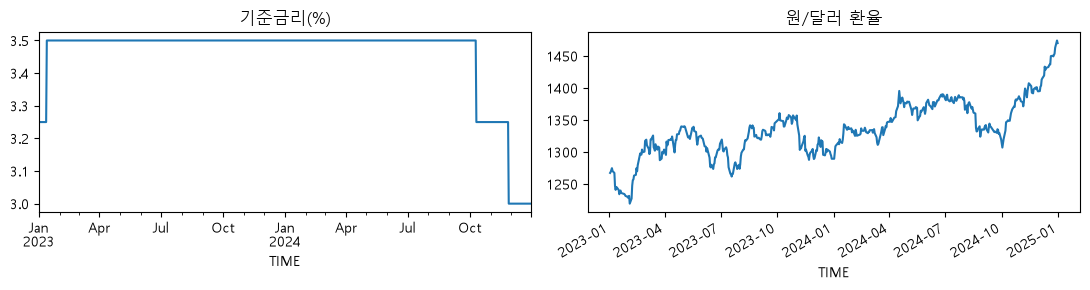

In [ ]:
# 기준금리와 원/달러 환율
base_rate = usdkrw_ecos = None
if ECOS_KEY:
    try:
        base_rate = ecos("722Y001", "D", "20230101", "20241231", "0101000") # 한국은행 기준금리
        usdkrw_ecos = ecos("731Y001", "D", "20230101", "20241231", "0000001") # 원/달러 환율

        display(base_rate.tail())
        display(usdkrw_ecos.tail())

        fig, ax = plt.subplots(1, 2, figsize=(11, 3))
        base_rate.plot(ax=ax[0], title="기준금리(%)")
        usdkrw_ecos.plot(ax=ax[1], title="원/달러 환율")
        plt.tight_layout(); plt.show()  # 칸 사이 여백을 조정해 글자 겹침을 막음
    except Exception as e:
        print("ECOS 오류:", e)
else:
    print("ECOS_API_KEY 없음 - 건너뜀")

# 해석
    # 기준금리: 값이 바뀐 시점에서만 변하는 계단 모양이 정상
    # 환율: 주말·공휴일 값이 없어서 날짜가 듬성듬성 비어도 정상

## 5. pykrx (KRX 시세, 투자지표, 수급)

**투자지표 정의**

| 지표 | 의미 | 계산 |
|---|---|---|
| EPS | 주당순이익 | 순이익 / 주식수 |
| PER | 주가수익비율 | 주가 / EPS |
| BPS | 주당순자산 | 자기자본 / 주식수 |
| PBR | 주가순자산비율 | 주가 / BPS |
| DIV | 배당수익률 | 주당배당금 / 주가 |

- PER, PBR이 낮으면 상대적으로 저평가일 수 있지만 ,실적 악화나 업황 문제로 낮은 경우도 많음(가치 함정)
- 단독 지표로 판단하지 않음
- 투자자별 거래 : 개인, 기관, 외국인의 순매수 금액을 보면 수급 주체를 파악할 수 있음
  : 순매수는 매수금액에서 매도금액을 뺀 값임

* 삼성전자 2024년 일별 시세(OHLCV) 조회와 종가 그래프(공개)
* 2024-12-30 기준 KOSPI 저PBR 종목 스크리닝
* 삼성전자의 투자자별 순매수(수급) 조회

* 시세 조회와 그래프

,시가,고가,저가,종가,거래량,등락률
날짜,,,,,,
2024-12-23,53400,54000,53300,53500,13672650,0.943396
2024-12-24,53700,54500,53600,54400,11634677,1.682243
2024-12-26,54500,54600,53500,53600,10517075,-1.470588
2024-12-27,53500,54100,53200,53700,10747196,0.186567
2024-12-30,53300,54000,53100,53200,12624702,-0.931099


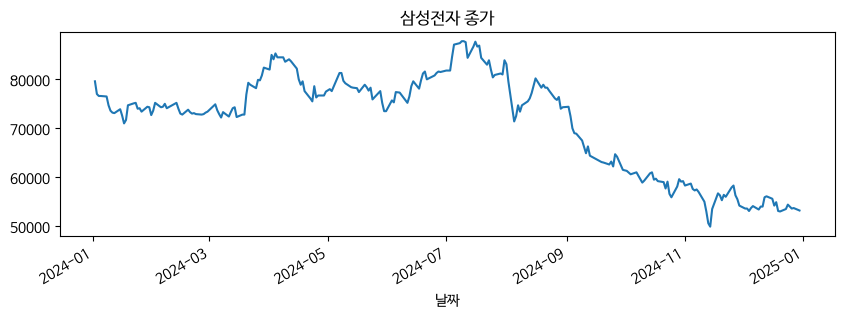

In [16]:
from pykrx import stock

try:
    ohlcv = stock.get_market_ohlcv("20240101", "20241231", "005930")
    display(ohlcv.tail())
    ohlcv["종가"].plot(title="삼성전자 종가", figsize=(10, 3)); plt.show()
except Exception as e:
    print("pykrx 시세 오류:", e)

* PBR 종목 스크리닝 (로그인 필요)

In [ ]:
# 2024-12-30 기준 KOSPI에서 PBR이 0 초과 0.6 미만인 종목 중, PBR이 가장 낮은 20개
if KRX_OK:
    try:
        # KOSPI 전 종목의 투자지표, 종목코드가 인덱스, 컬럼은 BPS, PER, PBR, EPS, DIV, DPS
        # market = ["KOSPI", "KOSDAQ", "KONEX", "ALL"]
        fund = stock.get_market_fundamental("20241230", market="KOSPI")
        # PBR > 0: PBR이 0인 종목을 걸러냄, 자본잠식이거나 지표를 산출할 수 없는 종목이 0으로 오는 경우가 있음
        # PBR < 0.6: 순자산(장부가치)의 60% 미만으로 거래되는 종목
            # BPS가 10,000원인 회사의 주가가 6,000원이면 PBR은 0.6
            # 시가총액이 순자산의 60% 수준

        low_pbr = fund[(fund["PBR"] > 0) & (fund["PBR"] < 0.6)].sort_values("PBR").head(20)
        display(low_pbr)
    except Exception as e:
        print("pykrx 투자지표 오류:", e)

# 해설
    # 저 PBR은 매수신호가 아님, PBR이 극단적으로 낮은 종목은 저평가가 아니라 수익성 악화, 지배구조 문제, 자산 가치 의심
    # 투자 후보를 거르는 1차 필터정도로 생각
    # PER > 0(흑자 여부), 부채비율 같은 조건을 더 확인하면 됨

,BPS,PER,PBR,EPS,DIV,DPS
티커,,,,,,
004960,66043,2.32,0.10,2757,1.56,100
000950,166586,0.00,0.11,0,0.00,0
021820,58958,1.31,0.12,5535,2.07,150
009440,6467,0.00,0.13,0,5.83,50
003240,4689721,0.00,0.13,0,0.29,1750
071840,54020,0.00,0.13,0,4.14,300
088350,17352,2.58,0.14,954,6.10,150
004020,145198,6.00,0.14,3506,4.75,1000
013580,90108,2.42,0.14,5334,3.10,400


* 투자자별 수급

In [ ]:
try:
    # 기간과 종목을 넣어 날짜별 투자자 유형(기관, 외국인, 개인 등)의 거래대금
    # 투자자 유형별 순매수 거래대금 시계열을 반환
    flow = stock.get_market_trading_value_by_date("20240101", "20241231", "005930")
    display(flow.tail())
except Exception as e:
    print("pykrx 수급 오류:", e)

# 양수 : 투자자가 그날 순매수 (산 금액 > 판 금액)
# 음수 : 투자자가 그날 순매도
# 모든 투자자의 순매수를 합치면 대략 0

,기관합계,기타법인,개인,외국인합계,전체
날짜,,,,,
2024-12-23,24961655300,57148805300,-37622295300,-44488165300,0
2024-12-24,3599664600,61666134600,-168358856200,103093057000,0
2024-12-26,-6930760500,67237626700,13274611300,-73581477500,0
2024-12-27,-13922536000,55601263000,-39507459700,-2171267300,0
2024-12-30,-3277287800,73455673600,72859108500,-143037494300,0


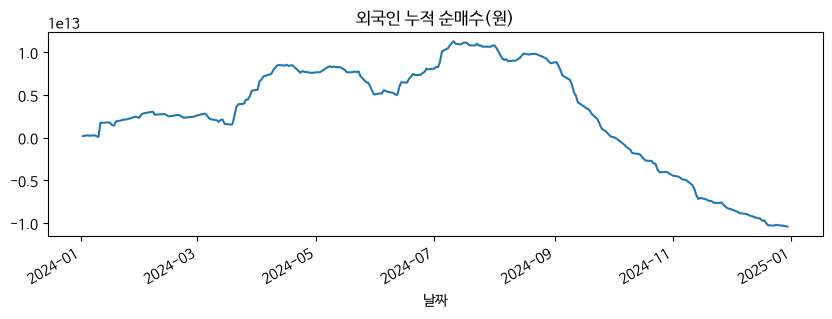

In [19]:
# 외국인 누적 순매수 추이
flow["외국인합계"].cumsum().plot(title="외국인 누적 순매수(원)", figsize=(10, 3))
plt.show()

In [20]:
# 억원 단위로 보기
display((flow / 1e8).round(0).tail())

,기관합계,기타법인,개인,외국인합계,전체
날짜,,,,,
2024-12-23,250.0,571.0,-376.0,-445.0,0.0
2024-12-24,36.0,617.0,-1684.0,1031.0,0.0
2024-12-26,-69.0,672.0,133.0,-736.0,0.0
2024-12-27,-139.0,556.0,-395.0,-22.0,0.0
2024-12-30,-33.0,735.0,729.0,-1430.0,0.0


In [ ]:
# 연간 투자자별 순매수 합계
# flow.sum() : 컬럼별로 세로 합계를 구함 
print((flow.sum() / 1e8).round(0))

기관합계     -39426.0
기타법인      22791.0
개인       120923.0
외국인합계   -104287.0
전체            0.0
dtype: float64
